# Effect shapes and interactions: preliminary exploration

This example fits an additive-plus-pairs model, inspects the changes suggested by a
preliminary tree ensemble, and checks the final prediction against a known mean
function. This controlled example distinguishes a straight effect, a smooth
curve, a jump and a pure interaction. It also includes a noise predictor.

The target is recovery of the mean response and its generating variables.
Each row is an independent simulated observation. Predictors are dimensionless;
responses have arbitrary response units. Six independent uniform $(-1,1)$
predictors generate

$$\mu(x)=2x_0+\sin(3x_1)+1.5\,1\{x_2>0.2\}+2x_3x_4,$$

with independent Gaussian noise of standard deviation 0.3. The sampling unit
and split unit are rows: 600 training rows and 1,200 independently generated test rows.
The estimands are test MSE, error in the estimated mean, and retained generating
variables. Tuning uses five training folds with a fixed seed. This is a
methodological example on simulated data; one simulation has no
replication-based uncertainty interval. Repeated seeds are an extension
in [](benchmark_preexploration.ipynb).

## Data and eligible predictors

The six predictors are drawn first, and the response is generated from them. `x5` is supplied as a candidate
with no effect. The two interaction variables have no separate main effect,
so weak marginal association alone must not exclude them. The truth is used
only when grading the fitted result; it is not supplied to autospec.

In [1]:
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")


RendererRegistry.enable('svg')

In [2]:
def simulate(seed, n):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1, 1, (n, 6))
    mean = (2 * x[:, 0] + np.sin(3 * x[:, 1]) + 1.5 * (x[:, 2] > 0.2)
            + 2 * x[:, 3] * x[:, 4])
    frame = pl.DataFrame({**{f"x{i}": x[:, i] for i in range(6)},
                          "y": mean + rng.normal(0, 0.3, n)})
    return frame, mean

train, _ = simulate(41, 600)
test, true_mean = simulate(42, 1200)


## Additive reference

A P-spline term `bbs(x)` (a penalized B-spline smooth) can estimate a curved
effect. The reference offers one for each predictor and tunes `mstop`, the number
of boosting updates, by five-fold cross-validation (CV). Its formula contains no
interaction, so it cannot express the product of `x3` and `x4` even with many
iterations.

In [3]:
formula = "y ~ " + " + ".join(f"bbs(x{i})" for i in range(6))
reference = mb.tune_mstop(formula, train, family=mb.Gaussian(), seed=4).model
print(f"Additive reference: {reference.mstop} iterations")


Additive reference: 198 iterations


## Screened specification

`budget=300` supplies room for shape comparisons, pair tuning and validation.
`interactions="adopt"` permits a suggested pair to enter only after the
held-out checks. `preexploration="native"` fits the preliminary tree ensemble
once; its importance ordering and partial-dependence diagnostics (the average
prediction of the ensemble as one predictor varies over its range) guide the
shape search and are reused for pair proposals. The Gaussian family is known
from the design and is supplied explicitly.

In [4]:
rec = mb.autospec(train, "y", family=mb.Gaussian(), budget=300, seed=4,
                  interactions="adopt", preexploration="native")
fit = rec.fit(train)
print(rec.formula)
print(f"Stopping iteration: {rec.mstop}; reported search cost: {rec.fits}")


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 66 is within 5% of the search cap 66; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 64 is within 5% of the search cap 66; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


y ~ bbs(x0, df=4.0) + bbs(x1, df=4.0) + btree(x2) + bbs(x3, df=2.5, knots=5) %X% bbs(x4, df=2.5, knots=5)
Stopping iteration: 11; reported search cost: 90


The formula contains a tree for the jump and a tensor term for the product.
`bbs(x3) %X% bbs(x4)` is a two-dimensional smooth surface over `x3` and `x4`; it
can represent a joint effect such as their product, which no sum of separate
main effects reproduces. The straight effect may remain represented by a smooth
when the folds do not support a meaningful gain from replacing it with a line.

## Proposed and selected shapes

The table "Shape proposals and generating roles" places the known generating
roles beside the shapes proposed by the preliminary ensemble and the shape chosen
by CV. The proposal may omit a shape only when the marginal and partial-dependence
diagnostics agree; ambiguous evidence retains all three. After the CV choice,
deselection drops each term whose share of the fitted risk reduction is below 1%
and keeps the smaller formula only if its CV risk is at most 1% higher, so the
final formula is the record of which terms are retained.

In [5]:
truth = {"x0": "line", "x1": "smooth curve", "x2": "jump",
         "x3": "interaction only", "x4": "interaction only", "x5": "noise"}
choices = {row.column: row.chosen for row in rec.evidence["shapes"]}
rows = [{"column": row["column"], "truth": truth[row["column"]],
         "importance": row["importance"], "proposed": ", ".join(row["shapes"]),
         "chosen": choices.get(row["column"], "not compared")}
        for row in rec.evidence["preexploration"]["columns"]]
table(pl.DataFrame(rows), title="Shape proposals and generating roles",
      subtitle="Permutation loss increase in squared response units; training data only",
      stub="column", stubhead="Predictor",
      labels={"truth": "Generating role", "importance": "Loss increase",
              "proposed": "Proposed shapes", "chosen": "CV choice"},
      notes=["Importance is predictive reliance of the preliminary ensemble, not evidence of a causal driver.",
             "The truth column grades the result and was not available to the search."])


GT(_tbl_data=shape: (6, 5)
┌────────┬──────────────────┬────────────┬──────────────────┬────────┐
│ column ┆ truth            ┆ importance ┆ proposed         ┆ chosen │
│ ---    ┆ ---              ┆ ---        ┆ ---              ┆ ---    │
│ str    ┆ str              ┆ f64        ┆ str              ┆ str    │
╞════════╪══════════════════╪════════════╪══════════════════╪════════╡
│ x0     ┆ line             ┆ 2.414253   ┆ bols, bbs        ┆ bbs    │
│ x1     ┆ smooth curve     ┆ 1.300744   ┆ bols, bbs, btree ┆ bbs    │
│ x2     ┆ jump             ┆ 1.061949   ┆ bbs, btree       ┆ btree  │
│ x3     ┆ interaction only ┆ 0.441882   ┆ bols, bbs, btree ┆ bbs    │
│ x4     ┆ interaction only ┆ 0.495905   ┆ bols, bbs, btree ┆ bbs    │
│ x5     ┆ noise            ┆ 0.024235   ┆ bols, bbs, btree ┆ bbs    │
└────────┴──────────────────┴────────────┴──────────────────┴────────┘, _body=<great_tables._gt_data.Body object at 0x10cd811f0>, _boxhead=Boxhead([ColInfo(var='column', type=<ColInfoTypeEnum.stub: 2>, column_label='column', column_align='left', column_width=None, stub_level=0), ColInfo(var='truth', type=<ColInfoTypeEnum.default: 1>, column_label='Generating role', column_align='left', column_width=None, stub_level=None), ColInfo(var='importance', type=<ColInfoTypeEnum.default: 1>, column_label='Loss increase', column_align='right', column_width=None, stub_level=None), ColInfo(var='proposed', type=<ColInfoTypeEnum.default: 1>, column_label='Proposed shapes', column_align='left', column_width=None, stub_level=None), ColInfo(var='chosen', type=<ColInfoTypeEnum.default: 1>, column_label='CV choice', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f771f40>, _spanners=Spanners([]), _heading=Heading(title='Shape proposals and generating roles', subtitle='Permutation loss increase in squared response units; training data only', preheader=None), _stubhead='Predictor', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f826b40>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10cfb7620>, _source_notes=['Importance is predictive reliance of the preliminary ensemble, not evidence of a causal driver.', 'The truth column grades the result and was not available to the search.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10cfb6ed0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10dd585f0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10cfb6d20>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='

## Interaction evidence

A pair's H² is the share of joint partial-dependence variation that is not
explained by its two separate partial dependences. Large H² for a negligible
surface is insufficient, so the screen also checks interaction variance.
The table "Interaction leads and adoption" lists each reported lead once per
proposed term form (a tensor smooth or a tree on the pair) and whether that form
was adopted after validation. A lead that cannot be validated within the remaining budget stays
a suggestion.

In [6]:
adopted = rec.evidence.get("adopted_interactions", ())
pairs = pl.DataFrame([{"pair": f"{lead.left} × {lead.right}",
                       "form": "tensor" if "%X%" in lead.term else lead.term.split("(")[0],
                       "source": lead.source, "h2": lead.h2,
                       "adopted": lead.term in adopted}
                      for lead in rec.evidence.get("interactions", ())])
pairs = pairs.with_columns(pl.col("h2").fill_nan(None))
table(pairs, title="Interaction leads and adoption",
      subtitle="H² is dimensionless; adoption is a held-out comparison",
      stub="pair", stubhead="Pair", labels={"form": "Term form", "source": "Screen", "h2": "H²",
                                            "adopted": "Adopted"},
      notes=["A residual-screen lead has no H²; a missing value does not mean zero interaction.",
             "Pairs are retained when removal costs at least 2% of risk or two paired fold standard errors."])

GT(_tbl_data=shape: (2, 5)
┌─────────┬────────┬────────────────────┬──────────┬─────────┐
│ pair    ┆ form   ┆ source             ┆ h2       ┆ adopted │
│ ---     ┆ ---    ┆ ---                ┆ ---      ┆ ---     │
│ str     ┆ str    ┆ str                ┆ f64      ┆ bool    │
╞═════════╪════════╪════════════════════╪══════════╪═════════╡
│ x3 × x4 ┆ tensor ┆ residual+surrogate ┆ 0.804647 ┆ true    │
│ x3 × x4 ┆ btree  ┆ residual+surrogate ┆ 0.804647 ┆ false   │
└─────────┴────────┴────────────────────┴──────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x10f576fc0>, _boxhead=Boxhead([ColInfo(var='pair', type=<ColInfoTypeEnum.stub: 2>, column_label='pair', column_align='left', column_width=None, stub_level=0), ColInfo(var='form', type=<ColInfoTypeEnum.default: 1>, column_label='Term form', column_align='left', column_width=None, stub_level=None), ColInfo(var='source', type=<ColInfoTypeEnum.default: 1>, column_label='Screen', column_align='left', column_width=None, stub_level=None), ColInfo(var='h2', type=<ColInfoTypeEnum.default: 1>, column_label='H²', column_align='right', column_width=None, stub_level=None), ColInfo(var='adopted', type=<ColInfoTypeEnum.default: 1>, column_label='Adopted', column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f7a27b0>, _spanners=Spanners([]), _heading=Heading(title='Interaction leads and adoption', subtitle='H² is dimensionless; adoption is a held-out comparison', preheader=None), _stubhead='Pair', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10fa7c3b0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10fa7e3c0>, _source_notes=['A residual-screen lead has no H²; a missing value does not mean zero interaction.', 'Pairs are retained when removal costs at least 2% of risk or two paired fold standard errors.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10fa7dd30>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10fa7e9c0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10fa7d1c0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'

## Fitted jump

The figure "Estimated and generating jump at x2 = 0.2" varies `x2` while holding the other predictors at zero,
which lies inside their training ranges. Centering both curves removes the
constant contribution from the other terms. The comparison checks the
estimated jump's location and magnitude, rather than only the selected learner
name.

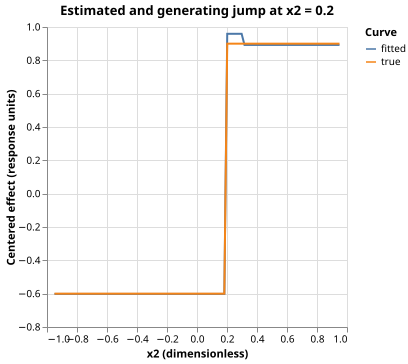

In [7]:
x2 = np.linspace(-0.95, 0.95, 100)
grid = pl.DataFrame({f"x{i}": x2 if i == 2 else np.zeros(100) for i in range(6)})
profile = np.asarray(fit.predict(grid)).ravel()
true_jump = 1.5 * (x2 > 0.2)
curves = pl.DataFrame({"x2": x2, "fitted": profile - profile.mean(),
                       "true": true_jump - true_jump.mean()})
chart_data = curves.unpivot(index="x2", variable_name="curve", value_name="effect")
chart = alt.Chart(chart_data).mark_line().encode(
    x=alt.X("x2:Q", title="x2 (dimensionless)"),
    y=alt.Y("effect:Q", title="Centered effect (response units)"),
    color=alt.Color("curve:N", title="Curve"),
).properties(title="Estimated and generating jump at x2 = 0.2")
display(chart)


## Test prediction and structural recovery

The independent test sample has not participated in screening, CV or
selection. Prediction MSE includes observation noise; mean-function MSE
compares with the noise-free generating mean. The oracle predicts with that true mean,
which no fitting method can access; its prediction MSE estimates the irreducible
noise variance, 0.3² = 0.09.
Its empirical prediction MSE is not a lower bound on every finite test sample.

In [8]:
from mboostrs.formula import term_variables

pred = np.asarray(fit.predict(test.drop("y"))).ravel()
base_pred = np.asarray(reference.predict(test.drop("y"))).ravel()
y_test = test["y"].to_numpy()
rows = []
for name, values in (("Additive reference", base_pred), ("Screened autospec", pred),
                     ("Known mean (oracle)", true_mean)):
    rows.append({"method": name, "mse": float(np.mean((y_test - values) ** 2)),
                 "signal_mse": float(np.mean((true_mean - values) ** 2))})
kept = set(term_variables(rec.formula.partition("~")[2]))
true_retained = len(kept & {"x0", "x1", "x2", "x3", "x4"})
false_retained = len(kept - {"x0", "x1", "x2", "x3", "x4"})


In [9]:
table(pl.DataFrame(rows), title="Prediction and mean-function recovery",
      subtitle="Independent test sample; squared response units; lower is better",
      labels={"mse": "Prediction MSE", "signal_mse": "Mean-function MSE"},
      spanners={"Test errors": ["mse", "signal_mse"]},
      better={"mse": "min", "signal_mse": "min"},
      notes=["One simulated training set and 1,200 independent test rows; no replication interval.",
             "The oracle's mean-function error is zero by construction."])


GT(_tbl_data=shape: (3, 3)
┌─────────────────────┬──────────┬────────────┐
│ method              ┆ mse      ┆ signal_mse │
│ ---                 ┆ ---      ┆ ---        │
│ str                 ┆ f64      ┆ f64        │
╞═════════════════════╪══════════╪════════════╡
│ Additive reference  ┆ 0.582127 ┆ 0.520088   │
│ Screened autospec   ┆ 0.1077   ┆ 0.018325   │
│ Known mean (oracle) ┆ 0.087074 ┆ 0.0        │
└─────────────────────┴──────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10fa89d00>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='Prediction MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_mse', type=<ColInfoTypeEnum.default: 1>, column_label='Mean-function MSE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10fabb170>, _spanners=Spanners([SpannerInfo(spanner_id='Test errors', spanner_level=0, spanner_label='Test errors', spanner_units=None, spanner_pattern=None, vars=['mse', 'signal_mse'], built=None)]), _heading=Heading(title='Prediction and mean-function recovery', subtitle='Independent test sample; squared response units; lower is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f84bef0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f849be0>, _source_notes=['One simulated training set and 1,200 independent test rows; no replication interval.', "The oracle's mean-function error is zero by construction."], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10fabb5f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10f8719d0>, <great_tables._gt_data.FormatInfo object at 0x10fabb620>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10fabb350>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_righ

The final formula retains {eval}`true_retained` of the five generating
variables and {eval}`false_retained` noise variables. Mean-function MSE is
{eval}`f"{rows[1]['signal_mse']:.4f}"` squared response units. The example
recovers the interaction without requiring marginal main effects for both
of its variables, but this one success does not establish selection-error
control, a bound on the rate at which noise predictors are retained across repeated samples. Importance and inner-fold diagnostics remain exploratory.

## Extension: screening modes

To repeat this search without preliminary trees, pass
`preexploration="off"`. To use the optional histogram engine, pass
`preexploration="hessboost"`; this mode requires mboostrs built with the optional
`hessboost` Cargo feature and raises an error otherwise. Compare the complete
workflows on new outer training/test splits, because selecting an engine from
this test result would make the same test error optimistic. The
[replicated benchmark](benchmark_preexploration.ipynb) records errors, failures,
shape comparisons and elapsed time for all three modes. The
[methodology chapter](../methodology/preexploration.ipynb) describes the
screening rules and their limits for correlated predictors.